In [1]:
from sqlalchemy import create_engine, text

engine = create_engine(
    "postgresql+psycopg://localhost:5432/postgres"
)

with engine.connect() as conn:
    result = conn.execute(text("SELECT current_database()"))
    print("Connected to:", result.scalar())

Connected to: postgres


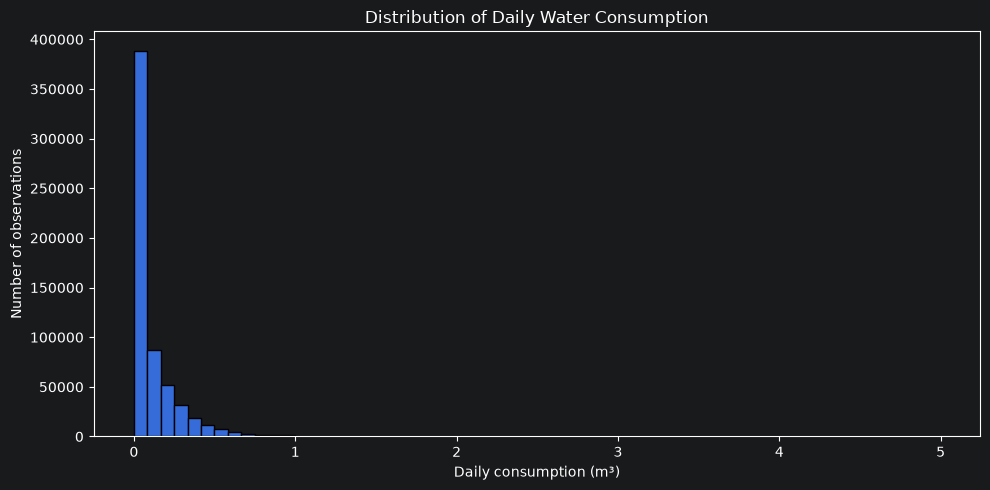

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

query = """
SELECT daily_m3
FROM vaviot.v_reading_deltas
WHERE daily_m3 >= 0
  AND daily_m3 <= 5
"""

df = pd.read_sql(query, engine)

plt.figure(figsize=(10, 5))
plt.hist(df["daily_m3"], bins=60, edgecolor="black")
plt.title("Distribution of Daily Water Consumption")
plt.xlabel("Daily consumption (m³)")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

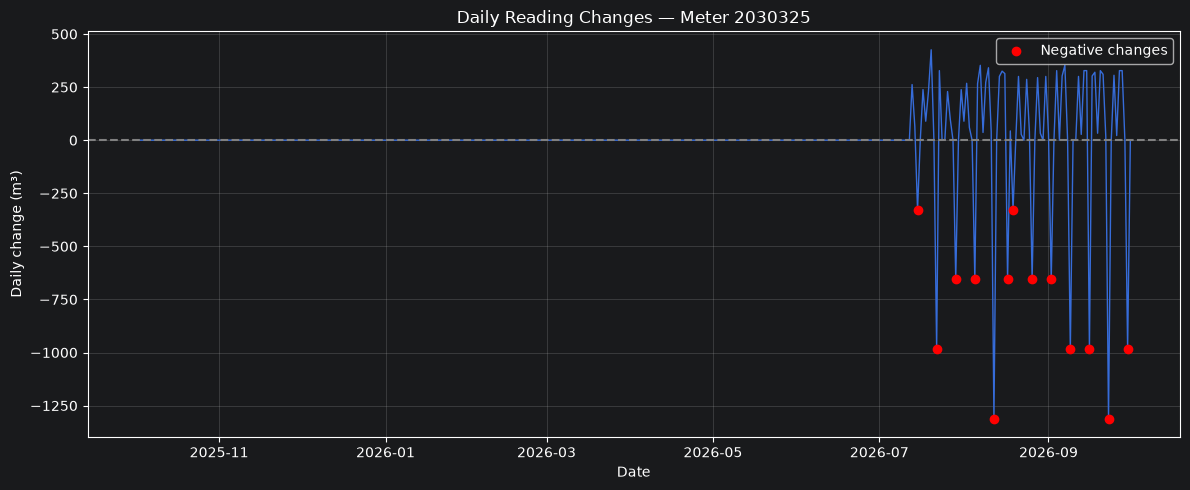

In [3]:
query = """
SELECT data, daily_m3
FROM vaviot.v_reading_deltas
WHERE anon_id = '2030325'
  AND daily_m3 IS NOT NULL
ORDER BY data
"""

meter = pd.read_sql(query, engine)
meter["data"] = pd.to_datetime(meter["data"])

plt.figure(figsize=(12, 5))
plt.plot(meter["data"], meter["daily_m3"], linewidth=1)
plt.scatter(
    meter.loc[meter["daily_m3"] < 0, "data"],
    meter.loc[meter["daily_m3"] < 0, "daily_m3"],
    color="red",
    label="Negative changes",
    zorder=3
)
plt.axhline(0, color="gray", linestyle="--")
plt.title("Daily Reading Changes — Meter 2030325")
plt.xlabel("Date")
plt.ylabel("Daily change (m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

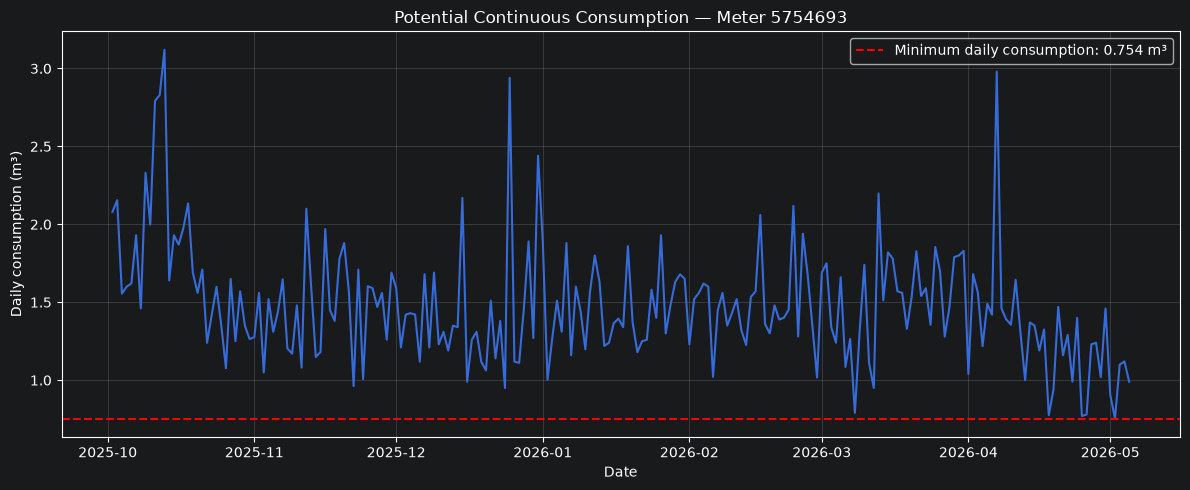

In [4]:
query = """
SELECT data, daily_m3
FROM vaviot.v_reading_deltas
WHERE anon_id = '5754693'
  AND data BETWEEN '2025-10-02' AND '2026-05-05'
ORDER BY data
"""

meter = pd.read_sql(query, engine)
meter["data"] = pd.to_datetime(meter["data"])

plt.figure(figsize=(12, 5))
plt.plot(meter["data"], meter["daily_m3"], linewidth=1.5)
plt.axhline(0.754, color="red", linestyle="--",
            label="Minimum daily consumption: 0.754 m³")

plt.title("Potential Continuous Consumption — Meter 5754693")
plt.xlabel("Date")
plt.ylabel("Daily consumption (m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

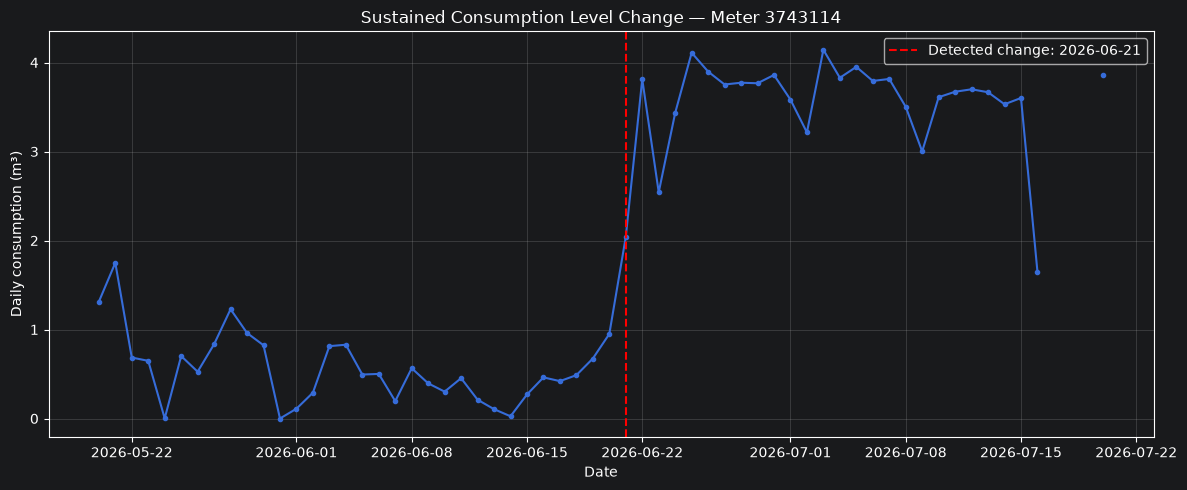

In [7]:
query = """
SELECT data, daily_m3
FROM vaviot.v_reading_deltas
WHERE anon_id = '3743114'
  AND data BETWEEN '2026-05-20' AND '2026-07-20'
ORDER BY data
"""

meter = pd.read_sql(query, engine)
meter["data"] = pd.to_datetime(meter["data"])

plt.figure(figsize=(12, 5))
plt.plot(meter["data"], meter["daily_m3"], marker="o", markersize=3)
plt.axvline(pd.Timestamp("2026-06-21"), color="red",
            linestyle="--", label="Detected change: 2026-06-21")

plt.title("Sustained Consumption Level Change — Meter 3743114")
plt.xlabel("Date")
plt.ylabel("Daily consumption (m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

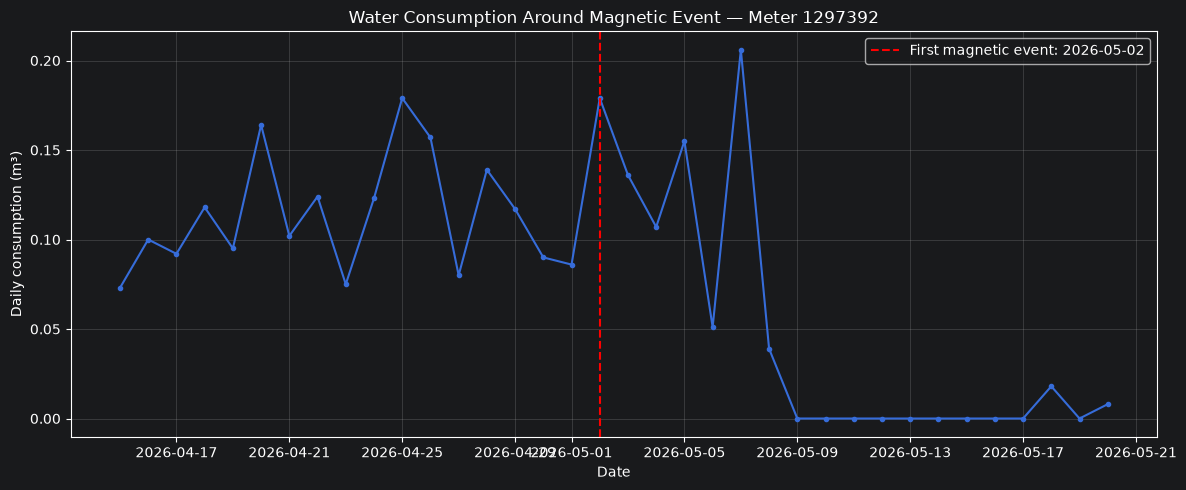

In [8]:
query = """
SELECT data, daily_m3
FROM vaviot.v_reading_deltas
WHERE anon_id = '1297392'
  AND data BETWEEN '2026-04-15' AND '2026-05-20'
ORDER BY data
"""

meter = pd.read_sql(query, engine)
meter["data"] = pd.to_datetime(meter["data"])

plt.figure(figsize=(12, 5))
plt.plot(meter["data"], meter["daily_m3"], marker="o", markersize=3)
plt.axvline(
    pd.Timestamp("2026-05-02"),
    color="red",
    linestyle="--",
    label="First magnetic event: 2026-05-02"
)

plt.title("Water Consumption Around Magnetic Event — Meter 1297392")
plt.xlabel("Date")
plt.ylabel("Daily consumption (m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Анализ магнитного события — прибор 1297392

Первое зарегистрированное событие «магнит» произошло 2 мая 2026 года.

После события суточное потребление воды продолжало колебаться в течение нескольких дней. Примерно с 9 мая наблюдался продолжительный период практически нулевого потребления.

При сравнении 14-дневных периодов до и после события медианный суточный расход снизился с 0.118 м³ до 0 м³, то есть на 100%.

Вывод: обнаружена временная связь между зарегистрированным магнитным событием и последующим снижением потребления воды. Однако снижение произошло не сразу после события, поэтому нельзя утверждать, что именно магнитное воздействие стало причиной изменения показаний.

Прибор 1297392 рекомендуется включить в список для дополнительной технической проверки.